# Build a Transformer Embedding Model From Scratch
**Data → vocabulary → tokenizer → transformer → embeddings → semantic search / Q&A**

| Stage | What we build | Well-known dataset | How we verify |
|---|---|---|---|
| 1 | Corpus cleaning | WikiText-103 | size / statistics |
| 2 | BPE tokenizer + vocabulary (pure Python) | WikiText-103 | compare with BERT's WordPiece vocab, Zipf curve |
| 3 | Transformer encoder + masked-language-model pre-training | WikiText-103 | loss curve, fill-in-the-blank |
| 4 | Sentence embeddings via contrastive learning | all-NLI | **STS-Benchmark** Spearman (published numbers exist) |
| 4b | **Retrieval fine-tuning** (question → answer sentence, hard negatives) | SQuAD v1.1 (train) | R@k / MRR on SQuAD dev |
| 5 | Semantic search / Q&A retriever | SQuAD v1.1 (dev) | Recall@k, MRR vs. a BM25 baseline |

Run top to bottom. Pick a preset in the next cell: `quick` (~20-30 min, shows the whole pipeline works) or `standard` (a few hours, better numbers).

In [8]:
%pip install -q datasets tokenizers matplotlib scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.


In [9]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os, re, json, math, time, random, unicodedata, heapq
from collections import Counter, defaultdict
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.sparse import csr_matrix
from datasets import load_dataset

PRESET = os.environ.get("PRESET", "standard")      # "quick" | "standard"  ("smoke" = tiny code check)
PRESETS = {
  "smoke":    dict(lines=3000,  vocab_size=600,  min_char=5,  min_word=1, d_model=64,  n_layers=2, n_heads=2, d_ff=128,  max_len=64,
                   mlm_steps=30,  mlm_bs=16,  lr=1e-3, nli_rows=600,  ft_steps=20,  ft_bs=16,  squad_q=100,  tsne_n=300, qa_rows=400, qa_steps=20),
  "quick":    dict(lines=150_000, vocab_size=8000,  min_char=50, min_word=3, d_model=256, n_layers=4, n_heads=4, d_ff=1024, max_len=128,
                   mlm_steps=4000, mlm_bs=128, lr=8e-4, nli_rows=100_000, ft_steps=800, ft_bs=128, squad_q=3000, tsne_n=3000, qa_rows=None, qa_steps=1500),
  "standard": dict(lines=None,    vocab_size=16000, min_char=50, min_word=3, d_model=384, n_layers=6, n_heads=6, d_ff=1536, max_len=128,
                   mlm_steps=30000, mlm_bs=128, lr=5e-4, nli_rows=None, ft_steps=4300, ft_bs=128, squad_q=None, tsne_n=6000, qa_rows=None, qa_steps=4000),
}
P = PRESETS[PRESET]
SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8      # RTX 3050 (Ampere) -> bf16, Colab T4 -> fp16
AMP_DTYPE = torch.bfloat16 if BF16 else torch.float16
def amp(): return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(DEVICE == "cuda"))
OUT = "artifacts"; os.makedirs(OUT, exist_ok=True)
METRICS, CURVES = {"preset": PRESET, "config": P}, {}
print(PRESET, "| device:", DEVICE, "| dtype:", AMP_DTYPE if DEVICE == "cuda" else "fp32",
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
# If you get a CUDA out-of-memory error (e.g. 4 GB GPU), lower mlm_bs / ft_bs in the preset.

standard | device: cuda | dtype: torch.bfloat16 | NVIDIA GeForce RTX 5090


## 1. Dataset: WikiText-103
~103M words of curated Wikipedia articles, a standard language-modelling benchmark. The raw version keeps original casing.
We drop section headings and undo WikiText's `@-@` number/hyphen markers.

In [ ]:
raw = list(load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1", split="train")["text"])
def clean_line(s):
    s = s.strip()
    if not s or s.startswith("="): return None            # blank lines and "= Heading =" lines
    return s.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
lines = [c for c in map(clean_line, raw[:P["lines"]] if P["lines"] else raw) if c]
del raw
print(f"{len(lines):,} paragraphs | {sum(len(l.split()) for l in lines)/1e6:.1f}M words")
print(lines[3][:300])

859,532 paragraphs | 96.8M words
As with previous Valkyira Chronicles games , Valkyria Chronicles III is a tactical role-playing game where players take control of a military unit and take part in missions against enemy forces . Stories are told through comic book-like panels with animated character portraits , with characters spea


## 2. Tokenizer + vocabulary, from scratch
**Byte-pair encoding (BPE):** start with single characters, repeatedly merge the most frequent adjacent pair into a new token.
We use BERT's notation: a word's first piece is bare (`play`), later pieces carry `##` (`##ing`).
Rare words are split into known pieces, so there are almost no unknown words.

In [ ]:
PRETOK = re.compile(r"\w+|[^\w\s]", re.UNICODE)
def normalize(t): return unicodedata.normalize("NFKC", t).lower()
def pretokenize(t): return PRETOK.findall(normalize(t))
SPECIALS = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]; PAD, UNK, CLS, SEP, MASK = range(5); N_SPECIAL = 5

class BPETokenizer:
    def __init__(self, vocab, merges):
        self.vocab, self.merges = vocab, merges
        self.tok2id = {t: i for i, t in enumerate(vocab)}
        self.ranks = {tuple(m): i for i, m in enumerate(merges)}
        self.cache = {}

    @classmethod
    def train(cls, word_counts, vocab_size, min_char=50, min_word=3, verbose=True):
        char_cnt = Counter()
        for w, c in word_counts.items():
            for ch in w: char_cnt[ch] += c
        alphabet = sorted(ch for ch, c in char_cnt.items() if c >= min_char)
        aset = set(alphabet)
        vocab = list(SPECIALS) + alphabet + ["##" + c for c in alphabet]; seen = set(vocab)
        words = [(w, c) for w, c in word_counts.items() if c >= min_word and all(ch in aset for ch in w)]
        W = [[w[0]] + ["##" + ch for ch in w[1:]] for w, _ in words]; Fq = [c for _, c in words]
        pc, where = defaultdict(int), defaultdict(set)
        for i, syms in enumerate(W):
            for p in zip(syms, syms[1:]): pc[p] += Fq[i]; where[p].add(i)
        heap = [(-c, p) for p, c in pc.items()]; heapq.heapify(heap); merges = []
        while len(vocab) < vocab_size and heap:
            negc, pair = heapq.heappop(heap); cur = pc.get(pair, 0)
            if cur != -negc:                                   # stale heap entry -> refresh
                if cur > 0: heapq.heappush(heap, (-cur, pair))
                continue
            if cur < 2: break
            a, b = pair; merged = a + b[2:]; changed = set()
            for i in list(where[pair]):
                syms = W[i]; new = []; j = 0
                while j < len(syms):
                    if j < len(syms) - 1 and syms[j] == a and syms[j + 1] == b: new.append(merged); j += 2
                    else: new.append(syms[j]); j += 1
                if len(new) == len(syms): continue
                for p in zip(syms, syms[1:]): pc[p] -= Fq[i]
                for p in zip(new, new[1:]): pc[p] += Fq[i]; where[p].add(i); changed.add(p)
                W[i] = new
            pc.pop(pair, None); where.pop(pair, None)
            for p in changed:
                if pc[p] > 0: heapq.heappush(heap, (-pc[p], p))
            merges.append(pair)
            if merged not in seen: seen.add(merged); vocab.append(merged)
            if verbose and len(merges) % 2000 == 0: print(f"  {len(merges):>6} merges, vocab {len(vocab)}, last: {a} + {b} -> {merged}")
        return cls(vocab, merges)

    def _word(self, w):
        syms = [w[0]] + ["##" + c for c in w[1:]]
        while len(syms) > 1:
            best, br = None, 1e18
            for i in range(len(syms) - 1):
                r = self.ranks.get((syms[i], syms[i + 1]))
                if r is not None and r < br: br, best = r, i
            if best is None: break
            syms[best:best + 2] = [syms[best] + syms[best + 1][2:]]
        ids = [self.tok2id.get(s, UNK) for s in syms]
        ids = [UNK] if UNK in ids else ids                      # any unknown char -> whole word [UNK] (like BERT)
        self.cache[w] = ids; return ids

    def encode_words(self, text):
        out = []; cache = self.cache
        for w in pretokenize(text): out.extend(cache.get(w) or self._word(w))
        return out

    def encode(self, text, max_len=None, add_special=True):
        ids = []
        for piece in re.split(r"(\[MASK\])", text):             # allow a literal [MASK] in the text
            ids.extend([MASK] if piece == "[MASK]" else self.encode_words(piece))
        if add_special:
            ids = ids[: (max_len - 2) if max_len else None]; ids = [CLS] + ids + [SEP]
        return ids

    def tokenize(self, text): return [self.vocab[i] for i in self.encode(text, add_special=False)]
    def decode(self, ids): return " ".join(self.vocab[i] for i in ids)
    def save(self, path): json.dump({"vocab": self.vocab, "merges": self.merges}, open(path, "w"))
    @classmethod
    def load(cls, path): d = json.load(open(path)); return cls(d["vocab"], [tuple(m) for m in d["merges"]])

In [13]:
t0 = time.time(); word_counts = Counter()
for i in range(0, len(lines), 50_000): word_counts.update(pretokenize("\n".join(lines[i:i + 50_000])))
print(f"{len(word_counts):,} distinct words, {sum(word_counts.values())/1e6:.1f}M total ({time.time()-t0:.0f}s)")
tok = BPETokenizer.train(word_counts, P["vocab_size"], P["min_char"], P["min_word"])
tok.save(f"{OUT}/tokenizer.json"); VOCAB = len(tok.vocab)
print("vocab size:", VOCAB, f"| trained in {time.time()-t0:.0f}s")
for s in ["The Eiffel Tower is located in Paris.", "Unbelievably, transformers tokenize antidisestablishmentarianism!"]:
    print(tok.tokenize(s))

531,064 distinct words, 100.5M total (20s)
    2000 merges, vocab 3071, last: n + ##orm -> norm
    4000 merges, vocab 5071, last: ##b + ##it -> ##bit
    6000 merges, vocab 7071, last: batt + ##ing -> batting
    8000 merges, vocab 9071, last: found + ##ing -> founding
   10000 merges, vocab 11071, last: eight + ##een -> eighteen
   12000 merges, vocab 13071, last: conf + ##ined -> confined
   14000 merges, vocab 15071, last: loc + ##als -> locals
vocab size: 16000 | trained in 30s
['the', 'e', '##iff', '##el', 'tower', 'is', 'located', 'in', 'paris', '.']
['un', '##bel', '##iev', '##ably', ',', 'transform', '##ers', 'to', '##ken', '##ize', 'ant', '##id', '##is', '##est', '##ab', '##lish', '##ment', '##arian', '##ism', '!']


### Verify the vocabulary
1. **Zipf's law** - token frequencies should fall on a near straight line in log-log space.
2. **Fertility** - average pieces per word (BERT's WordPiece is ≈1.2-1.4 on English text).
3. **Compare with `bert-base-uncased`** - same `##` notation, so we can measure vocabulary overlap directly.

115.9M tokens (20s)
fertility 1.15 tokens/word | [UNK] rate 0.0121%


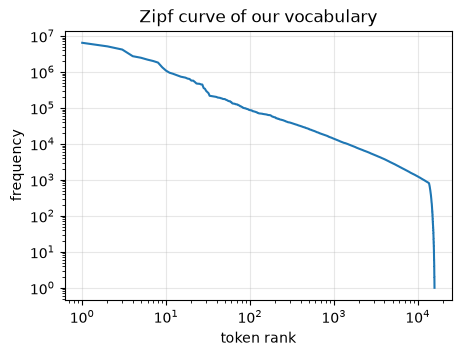

10 most frequent tokens: ['the', ',', '.', 'of', 'and', 'in', 'to', 'a', '"', 'was']


In [14]:
def encode_corpus(lines, chunk=20_000):
    out = []
    for i in range(0, len(lines), chunk):
        ids = []
        for l in lines[i:i + chunk]: ids.extend(tok.encode_words(l)); ids.append(SEP)
        out.append(np.array(ids, dtype=np.uint16))
    return np.concatenate(out)
t0 = time.time(); stream = encode_corpus(lines); print(f"{len(stream)/1e6:.1f}M tokens ({time.time()-t0:.0f}s)")
freq = np.bincount(stream, minlength=VOCAB)
n_words = sum(word_counts.values()); fert = (len(stream) - len(lines)) / n_words
unk_rate = freq[UNK] / len(stream)
print(f"fertility {fert:.2f} tokens/word | [UNK] rate {unk_rate:.4%}")
METRICS["tokenizer"] = dict(vocab_size=VOCAB, fertility=float(fert), unk_rate=float(unk_rate), corpus_tokens=int(len(stream)))

top = np.sort(freq[N_SPECIAL:])[::-1]; top = top[top > 0]
plt.figure(figsize=(5, 3.5)); plt.loglog(np.arange(1, len(top) + 1), top); plt.xlabel("token rank"); plt.ylabel("frequency")
plt.title("Zipf curve of our vocabulary"); plt.grid(alpha=.3); plt.show()
print("10 most frequent tokens:", [tok.vocab[i] for i in np.argsort(-freq)[:10]])

In [15]:
stsb = {s: load_dataset("sentence-transformers/stsb", split=s) for s in ["validation", "test"]}
sample = list(stsb["test"]["sentence1"])[:500]
try:
    from tokenizers import Tokenizer
    bert = Tokenizer.from_pretrained("bert-base-uncased")
    bert_vocab = set(bert.get_vocab())
    overlap = len(bert_vocab & set(tok.vocab)) / VOCAB
    nw = sum(len(pretokenize(s)) for s in sample)
    f_ours = sum(len(tok.encode_words(s)) for s in sample) / nw
    f_bert = sum(len(bert.encode(s, add_special_tokens=False).ids) for s in sample) / nw
    print(f"{overlap:.0%} of our vocab also appears in BERT's | fertility on STS-B text: ours {f_ours:.2f} vs BERT {f_bert:.2f}")
    s = "The cat sat on the mat while astronomers observed exoplanets."
    print("ours:", tok.tokenize(s)); print("bert:", bert.encode(s, add_special_tokens=False).tokens)
    METRICS["tokenizer"].update(bert_overlap=float(overlap), fertility_ours_stsb=f_ours, fertility_bert_stsb=f_bert)
except Exception as e: print("BERT comparison skipped:", e)

76% of our vocab also appears in BERT's | fertility on STS-B text: ours 1.10 vs BERT 1.02
ours: ['the', 'cat', 'sat', 'on', 'the', 'mat', 'while', 'astronom', '##ers', 'observed', 'ex', '##op', '##lan', '##ets', '.']
bert: ['the', 'cat', 'sat', 'on', 'the', 'mat', 'while', 'astronomers', 'observed', 'ex', '##op', '##lane', '##ts', '.']


## 3. The transformer encoder (written with plain PyTorch layers)
Token embedding + position embedding → N × [self-attention → feed-forward] with residual connections and LayerNorm.
Self-attention: `softmax(QKᵀ/√d)·V`, run in several heads. Padding positions are masked out.
The "manual" attention path (used when we want to *see* attention) is checked against PyTorch's fused kernel below.

In [16]:
class Attention(nn.Module):
    def __init__(s, d, h, p):
        super().__init__(); s.h, s.dh, s.p = h, d // h, p
        s.qkv, s.out = nn.Linear(d, 3 * d), nn.Linear(d, d)
    def forward(s, x, keep, return_attn=False):                 # keep: (B,T) bool, True = real token
        B, T, _ = x.shape
        q, k, v = s.qkv(x).view(B, T, 3, s.h, s.dh).permute(2, 0, 3, 1, 4)
        if return_attn:                                         # explicit formula
            sc = (q @ k.transpose(-2, -1)) / math.sqrt(s.dh)
            sc = sc.masked_fill(~keep[:, None, None, :], float("-inf"))
            a = sc.softmax(-1); o = F.dropout(a, s.p, s.training) @ v
        else:                                                   # same maths, fused kernel
            a = None; o = F.scaled_dot_product_attention(q, k, v, attn_mask=keep[:, None, None, :], dropout_p=s.p if s.training else 0.0)
        return s.out(o.transpose(1, 2).reshape(B, T, -1)), a

class Block(nn.Module):
    def __init__(s, d, h, dff, p):
        super().__init__(); s.ln1, s.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.attn = Attention(d, h, p); s.ff = nn.Sequential(nn.Linear(d, dff), nn.GELU(), nn.Linear(dff, d)); s.drop = nn.Dropout(p)
    def forward(s, x, keep, return_attn=False):
        a_out, a = s.attn(s.ln1(x), keep, return_attn); x = x + s.drop(a_out)
        return x + s.drop(s.ff(s.ln2(x))), a

class Encoder(nn.Module):
    def __init__(s, vocab, d, L, h, dff, max_len, p=0.1):
        super().__init__(); s.cfg = dict(vocab=vocab, d=d, L=L, h=h, dff=dff, max_len=max_len, p=p)
        s.tok_emb, s.pos_emb = nn.Embedding(vocab, d, padding_idx=PAD), nn.Embedding(max_len, d)
        s.ln_emb, s.drop = nn.LayerNorm(d), nn.Dropout(p)
        s.blocks = nn.ModuleList(Block(d, h, dff, p) for _ in range(L)); s.ln_f = nn.LayerNorm(d)
        s.apply(s._init)
        for b in s.blocks:                                      # GPT-2 style: shrink residual-branch outputs
            for lin in (b.attn.out, b.ff[2]): nn.init.normal_(lin.weight, std=0.02 / math.sqrt(2 * L))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)
    def forward(s, ids, return_attn=False):
        keep = ids != PAD; x = s.tok_emb(ids) + s.pos_emb(torch.arange(ids.shape[1], device=ids.device))
        x = s.drop(s.ln_emb(x)); attns = []
        for b in s.blocks:
            x, a = b(x, keep, return_attn); attns.append(a)
        return s.ln_f(x), attns

class MLM(nn.Module):                                           # encoder + masked-word prediction head (tied embeddings)
    def __init__(s, enc):
        super().__init__(); d = enc.cfg["d"]; s.enc = enc
        s.dense, s.ln, s.bias = nn.Linear(d, d), nn.LayerNorm(d), nn.Parameter(torch.zeros(enc.cfg["vocab"]))
    def logits(s, h): return s.ln(F.gelu(s.dense(h))) @ s.enc.tok_emb.weight.T + s.bias
    def forward(s, ids, labels):
        h, _ = s.enc(ids); sel = labels != -100                  # only compute logits where a word was masked
        return F.cross_entropy(s.logits(h[sel]).float(), labels[sel])

def new_encoder(): return Encoder(VOCAB, P["d_model"], P["n_layers"], P["n_heads"], P["d_ff"], P["max_len"]).to(DEVICE)
def mean_pool(h, keep): k = keep.unsqueeze(-1).to(h.dtype); return (h * k).sum(1) / k.sum(1).clamp(min=1)
def pad_batch(seqs):
    T = max(map(len, seqs)); out = torch.full((len(seqs), T), PAD, dtype=torch.long)
    for i, s in enumerate(seqs): out[i, :len(s)] = torch.tensor(s)
    return out

# sanity checks: fused attention == explicit formula; padding doesn't change a sentence's embedding
_e = new_encoder().eval(); _x = pad_batch([tok.encode("a quick test sentence", 32), tok.encode("hi", 32)]).to(DEVICE)
with torch.no_grad():
    _a, _ = _e(_x); _b, _ = _e(_x, return_attn=True)
    _n2 = len(tok.encode("hi", 32)); _solo, _ = _e(_x[1:2, :_n2])
print("fused vs explicit attention max diff:", (_a - _b).abs().max().item())
print("padding-invariance max diff:", (_a[1, :_n2] - _solo[0]).abs().max().item())
n_params = sum(p.numel() for p in _e.parameters()); print(f"encoder parameters: {n_params/1e6:.1f}M"); METRICS["params_millions"] = n_params / 1e6
del _e, _x

fused vs explicit attention max diff: 5.960464477539062e-07
padding-invariance max diff: 0.0
encoder parameters: 16.8M


## 4a. Pre-training: masked language modelling (BERT's objective)
Hide 15% of the tokens (80% → `[MASK]`, 10% → random token, 10% unchanged) and train the model to recover them.
This is where the model learns what words mean from context. It needs no labels, only raw text.

In [17]:
L = P["max_len"]
n_blocks = len(stream) // (L - 1)
blocks = stream[: n_blocks * (L - 1)].reshape(n_blocks, L - 1)
print(f"{n_blocks:,} training sequences of {L} tokens")

def mask_tokens(ids, p=0.15):
    labels = ids.clone(); prob = torch.full(ids.shape, p, device=ids.device); prob[ids < N_SPECIAL] = 0
    m = torch.bernoulli(prob).bool(); labels[~m] = -100
    r = torch.rand(ids.shape, device=ids.device); inp = ids.clone()
    inp[m & (r < 0.8)] = MASK
    rnd = m & (r >= 0.8) & (r < 0.9); inp[rnd] = torch.randint(N_SPECIAL, VOCAB, ids.shape, device=ids.device)[rnd]
    return inp, labels

def lr_at(step, total, peak, warm=0.06):
    w = max(1, int(total * warm))
    return peak * step / w if step < w else peak * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - w) / max(1, total - w))))

def make_opt(model, lr):
    decay = [p for n, p in model.named_parameters() if p.ndim >= 2]; no = [p for n, p in model.named_parameters() if p.ndim < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": 0.01}, {"params": no, "weight_decay": 0.0}], lr=lr, betas=(0.9, 0.98))

scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and not BF16))
def step_opt(model, opt, loss, lr):
    for g in opt.param_groups: g["lr"] = lr
    opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update()

enc = new_encoder(); mlm = MLM(enc).to(DEVICE); opt = make_opt(mlm, P["lr"])
steps, bs = P["mlm_steps"], P["mlm_bs"]; CURVES["mlm"] = []; run = []; t0 = time.time(); mlm.train()
for step in range(steps):
    idx = np.random.randint(0, n_blocks, bs)
    x = torch.from_numpy(blocks[idx].astype(np.int64)); x = torch.cat([torch.full((bs, 1), CLS), x], 1).to(DEVICE)
    inp, lab = mask_tokens(x)
    with amp(): loss = mlm(inp, lab)
    step_opt(mlm, opt, loss, lr_at(step, steps, P["lr"])); run.append(loss.item())
    if (step + 1) % max(1, steps // 40) == 0 or step == steps - 1:
        CURVES["mlm"].append((step + 1, float(np.mean(run)))); run = []
    if (step + 1) % max(1, steps // 10) == 0:
        print(f"step {step+1:>6}/{steps}  loss {CURVES['mlm'][-1][1]:.3f}  ({(time.time()-t0)/60:.1f} min)")
torch.save({"cfg": enc.cfg, "state": enc.state_dict()}, f"{OUT}/encoder_mlm.pt")
METRICS["mlm_final_loss"] = CURVES["mlm"][-1][1]; METRICS["mlm_minutes"] = (time.time() - t0) / 60

912,615 training sequences of 128 tokens
step   3000/30000  loss 6.246  (0.7 min)
step   6000/30000  loss 3.919  (1.5 min)
step   9000/30000  loss 3.410  (2.2 min)
step  12000/30000  loss 3.181  (2.9 min)
step  15000/30000  loss 3.034  (3.7 min)
step  18000/30000  loss 2.927  (4.4 min)
step  21000/30000  loss 2.842  (5.2 min)
step  24000/30000  loss 2.776  (5.9 min)
step  27000/30000  loss 2.734  (6.6 min)
step  30000/30000  loss 2.716  (7.4 min)


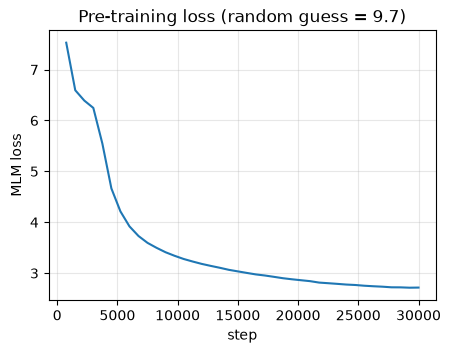

The capital of France is [MASK]. -> [('unknown', 0.071), ('now', 0.051), ('destroyed', 0.037), ('today', 0.032), ('lost', 0.021)]
He was born in [MASK] and died in 1990. -> [('1990', 0.09), ('1989', 0.056), ('1991', 0.045), ('1988', 0.03), ('1983', 0.03)]
The [MASK] won the football match. -> [('club', 0.209), ('team', 0.144), ('match', 0.036), ('referee', 0.034), ('side', 0.016)]


In [18]:
plt.figure(figsize=(5, 3.5)); xs, ys = zip(*CURVES["mlm"]); plt.plot(xs, ys); plt.xlabel("step"); plt.ylabel("MLM loss")
plt.title(f"Pre-training loss (random guess = {math.log(VOCAB):.1f})"); plt.grid(alpha=.3); plt.show()

@torch.no_grad()
def fill_mask(text, k=5):
    mlm.eval(); ids = torch.tensor([tok.encode(text)], device=DEVICE); pos = (ids[0] == MASK).nonzero().item()
    with amp(): h, _ = enc(ids)
    pr = mlm.logits(h[0, pos]).float(); pr[:N_SPECIAL] = -1e9; pr = pr.softmax(-1); top = pr.topk(k)
    return [(tok.vocab[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]
for s in ["The capital of France is [MASK].", "He was born in [MASK] and died in 1990.", "The [MASK] won the football match."]:
    print(s, "->", fill_mask(s))

## 4b. Turning the language model into a *sentence embedding* model
Mean-pooling token vectors from an MLM-only model gives poor sentence embeddings.
Fix (Sentence-BERT idea): **contrastive learning** on sentence pairs. For each *premise* in the NLI dataset we have a sentence it
*entails* (positive) and one it *contradicts* (hard negative). Train so that `cos(premise, positive)` beats `cos(premise, everything else in the batch)`.
Loss = cross-entropy over the similarity matrix ("InfoNCE" / multiple-negatives ranking loss).

In [19]:
@torch.no_grad()
def encode_texts(model, texts, bs=256, max_len=128):
    model.eval(); texts = list(texts); order = np.argsort([len(t) for t in texts]); out = None
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]; ids = pad_batch([tok.encode(texts[j], max_len) for j in idx]).to(DEVICE)
        with amp(): h, _ = model(ids)
        e = F.normalize(mean_pool(h.float(), ids != PAD), dim=-1).cpu().numpy()
        if out is None: out = np.zeros((len(texts), e.shape[1]), dtype=np.float32)
        out[idx] = e
    return out

def sts_eval(encode_fn, split):
    d = stsb[split]; a, b = encode_fn(list(d["sentence1"])), encode_fn(list(d["sentence2"]))
    return float(spearmanr((a * b).sum(1), list(d["score"])).correlation)

STS = {}
for name, m in [("random_init", new_encoder()), ("after_mlm", enc)]:
    STS[name] = {s: sts_eval(lambda t: encode_texts(m, t), s) for s in stsb}
    print(f"{name:>12}: STS-B val {STS[name]['validation']:.3f} | test {STS[name]['test']:.3f}")

 random_init: STS-B val 0.561 | test 0.471
   after_mlm: STS-B val 0.594 | test 0.467


In [20]:
nli = load_dataset("sentence-transformers/all-nli", "triplet", split="train")
n = min(len(nli), P["nli_rows"] or len(nli))
A, Pos, Neg = (list(nli[c])[:n] for c in ["anchor", "positive", "negative"])
enc_ids = lambda xs: [tok.encode(x, 64) for x in xs]
A, Pos, Neg = enc_ids(A), enc_ids(Pos), enc_ids(Neg); print(f"{n:,} NLI triplets, e.g. {tok.decode(A[0][1:-1])} | {tok.decode(Pos[0][1:-1])}")

SCALE = 20.0                                                    # temperature: cosine * 20 before softmax
steps, bs = P["ft_steps"], P["ft_bs"]; FT_LR = 1e-3 if PRESET == "smoke" else 1e-4; opt = make_opt(enc, FT_LR)
CURVES["ft"], CURVES["sts_val"] = [], []; run = []; perm = np.random.permutation(n); ptr = 0; t0 = time.time()
eval_every = max(1, steps // 10)
for step in range(steps):
    if ptr + bs > n: perm = np.random.permutation(n); ptr = 0
    ix = perm[ptr:ptr + bs]; ptr += bs; enc.train()
    ids = pad_batch([A[i] for i in ix] + [Pos[i] for i in ix] + [Neg[i] for i in ix]).to(DEVICE)
    with amp(): h, _ = enc(ids)
    e = F.normalize(mean_pool(h.float(), ids != PAD), dim=-1); a, cand = e[:bs], e[bs:]      # candidates: all positives + all negatives
    loss = F.cross_entropy(a @ cand.T * SCALE, torch.arange(bs, device=DEVICE))
    step_opt(enc, opt, loss, lr_at(step, steps, FT_LR)); run.append(loss.item())
    if (step + 1) % max(1, steps // 40) == 0: CURVES["ft"].append((step + 1, float(np.mean(run)))); run = []
    if (step + 1) % eval_every == 0 or step == 0:
        CURVES["sts_val"].append((step + 1, sts_eval(lambda t: encode_texts(enc, t), "validation")))
        print(f"step {step+1:>5}/{steps}  loss {loss.item():.3f}  STS-B val Spearman {CURVES['sts_val'][-1][1]:.3f}  ({(time.time()-t0)/60:.1f} min)")
STS["after_contrastive"] = {s: sts_eval(lambda t: encode_texts(enc, t), s) for s in stsb}
METRICS["sts"] = STS; METRICS["ft_minutes"] = (time.time() - t0) / 60
torch.save({"cfg": enc.cfg, "state": enc.state_dict()}, f"{OUT}/encoder.pt")

557,850 NLI triplets, e.g. a person on a horse j ##umps over a broken down airpl ##ane . | a person is outd ##o ##ors , on a horse .
step     1/4300  loss 4.097  STS-B val Spearman 0.594  (0.0 min)
step   430/4300  loss 1.538  STS-B val Spearman 0.781  (0.1 min)
step   860/4300  loss 1.191  STS-B val Spearman 0.791  (0.3 min)
step  1290/4300  loss 1.096  STS-B val Spearman 0.794  (0.4 min)
step  1720/4300  loss 1.110  STS-B val Spearman 0.797  (0.5 min)
step  2150/4300  loss 0.752  STS-B val Spearman 0.799  (0.7 min)
step  2580/4300  loss 0.856  STS-B val Spearman 0.799  (0.8 min)
step  3010/4300  loss 0.997  STS-B val Spearman 0.801  (0.9 min)
step  3440/4300  loss 0.917  STS-B val Spearman 0.799  (1.1 min)
step  3870/4300  loss 0.891  STS-B val Spearman 0.800  (1.2 min)
step  4300/4300  loss 0.817  STS-B val Spearman 0.801  (1.3 min)


### Verify the embedding model on STS-Benchmark
STS-B has 1,379 test sentence pairs scored 0-5 by humans. We embed both sentences, take the cosine similarity and report Spearman correlation with the human scores.
Published reference points (Reimers & Gurevych, 2019, STS-B test ×100): averaged GloVe vectors **≈58**, SBERT-NLI-base (110M params, pre-trained on far more text) **≈77**.
A small model trained from scratch should land between a random network and those numbers. That is the honest, expected outcome.

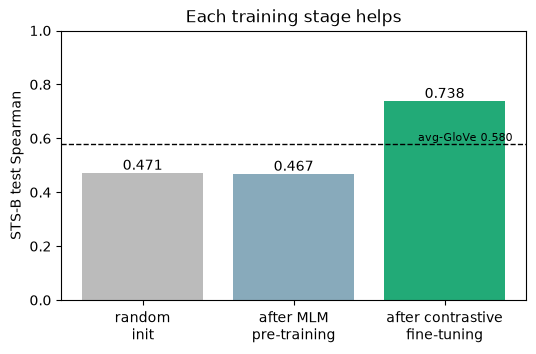

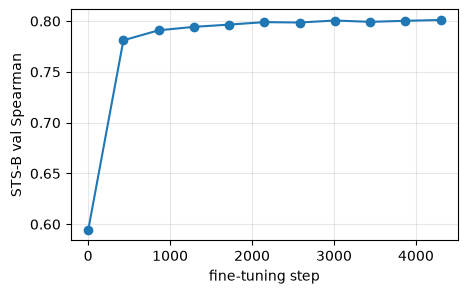

In [21]:
names = ["random_init", "after_mlm", "after_contrastive"]; vals = [STS[k]["test"] for k in names]
plt.figure(figsize=(6, 3.5)); bars = plt.bar(["random\ninit", "after MLM\npre-training", "after contrastive\nfine-tuning"], vals, color=["#bbb", "#8ab", "#2a7"])
plt.bar_label(bars, fmt="%.3f"); plt.axhline(0.5802, ls="--", c="k", lw=1); plt.text(2.45, 0.5802 + .01, "avg-GloVe 0.580", ha="right", fontsize=8)
plt.ylabel("STS-B test Spearman"); plt.title("Each training stage helps"); plt.ylim(0, 1); plt.show()
xs, ys = zip(*CURVES["sts_val"]); plt.figure(figsize=(5, 3)); plt.plot(xs, ys, "o-"); plt.xlabel("fine-tuning step"); plt.ylabel("STS-B val Spearman"); plt.grid(alpha=.3); plt.show()

## 5. Do the embeddings look right?
Three quick sanity checks you can show live.
**(a)** Nearest neighbours of a word in the learned *token embedding table*.
**(b)** Do words of the same category (countries, colours, numbers...) cluster in the final embedding space?
**(c)** A sentence-similarity matrix: paraphrases should light up, unrelated sentences should not.

In [22]:
def neighbors(word, k=6):
    E = F.normalize(enc.tok_emb.weight.detach().float(), dim=-1); i = tok.tok2id[word]
    s = E @ E[i]; s[:N_SPECIAL] = -1; top = s.topk(k + 1)
    return [tok.vocab[j] for j in top.indices.tolist() if j != i][:k]
for w in ["paris", "january", "football", "river", "seven", "blue", "war"]:
    if w in tok.tok2id: print(f"{w:>9} ->", neighbors(w))

    paris -> ['tokyo', 'switzerland', 'vienna', 'beijing', 'munich', 'moscow']
  january -> ['february', 'december', 'july', 'november', 'october', 'april']
 football -> ['cricket', 'basketball', 'soccer', 'midfield', 'baseball', 'rugby']
    river -> ['canal', 'rivers', 'thames', 'rhine', 'creek', 'peninsula']
    seven -> ['nine', 'eight', 'twelve', 'thirteen', 'eleven', 'six']
     blue -> ['purple', 'yellow', 'orange', 'grey', 'colors', 'colours']
      war -> ['wars', 'conflict', 'peace', 'military', 'rebellion', 'battle']


67 words | mean cosine within category 0.65 vs across categories 0.42 | nearest-centroid accuracy 97%


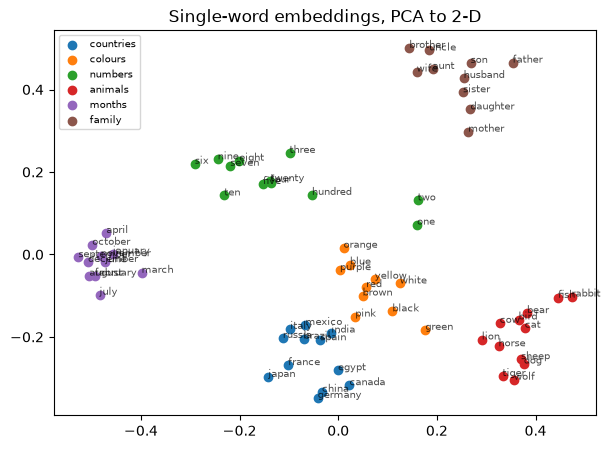

In [23]:
GROUPS = {
 "countries": "france germany japan brazil india canada italy spain china russia egypt mexico".split(),
 "colours":   "red blue green yellow black white orange purple pink brown".split(),
 "numbers":   "one two three four five six seven eight nine ten twenty hundred".split(),
 "animals":   "dog cat horse bird fish lion tiger wolf bear rabbit sheep cow".split(),
 "months":    "january february march april june july august september october november december".split(),
 "family":    "mother father brother sister son daughter wife husband uncle aunt".split(),
}
words, labels = [], []
for g, ws in GROUPS.items():
    for w in ws:
        if w in tok.tok2id: words.append(w); labels.append(g)         # keep only words that are a single token
V = encode_texts(enc, words); lab = np.array(labels)
S = V @ V.T; same = lab[:, None] == lab[None, :]; np.fill_diagonal(same, False)
intra, inter = S[same].mean(), S[lab[:, None] != lab[None, :]].mean()
# leave-one-out: classify each word by its most similar group centroid
acc = np.mean([max(GROUPS, key=lambda g: (V[i] @ V[(lab == g) & (np.arange(len(lab)) != i)].mean(0)) if ((lab == g) & (np.arange(len(lab)) != i)).any() else -9) == lab[i] for i in range(len(lab))])
print(f"{len(words)} words | mean cosine within category {intra:.2f} vs across categories {inter:.2f} | nearest-centroid accuracy {acc:.0%}")
METRICS["word_groups"] = dict(n=len(words), intra=float(intra), inter=float(inter), centroid_acc=float(acc))
from sklearn.decomposition import PCA
xy = PCA(2).fit_transform(V); plt.figure(figsize=(7, 5))
for g in GROUPS:
    m = lab == g; plt.scatter(xy[m, 0], xy[m, 1], label=g)
for (x, y), w in zip(xy, words): plt.annotate(w, (x, y), fontsize=7, alpha=.7)
plt.legend(fontsize=7); plt.title("Single-word embeddings, PCA to 2-D"); plt.show()

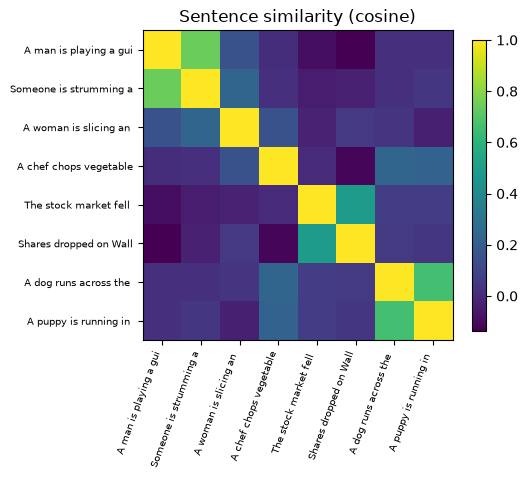

In [24]:
sents = ["A man is playing a guitar.", "Someone is strumming a guitar.", "A woman is slicing an onion.", "A chef chops vegetables in a kitchen.",
         "The stock market fell sharply today.", "Shares dropped on Wall Street this afternoon.", "A dog runs across the grass.", "A puppy is running in a field."]
E_ = encode_texts(enc, sents); S = E_ @ E_.T
plt.figure(figsize=(5.5, 5)); plt.imshow(S, cmap="viridis"); plt.colorbar(shrink=.8)
plt.xticks(range(len(sents)), [s[:22] for s in sents], rotation=70, ha="right", fontsize=7); plt.yticks(range(len(sents)), [s[:22] for s in sents], fontsize=7)
plt.title("Sentence similarity (cosine)"); plt.tight_layout(); plt.show()

### See what attention is doing
Each head in the last layer decides, for every token, which other tokens to read from. Different heads often specialise (neighbouring tokens, `[SEP]`, punctuation, related words).

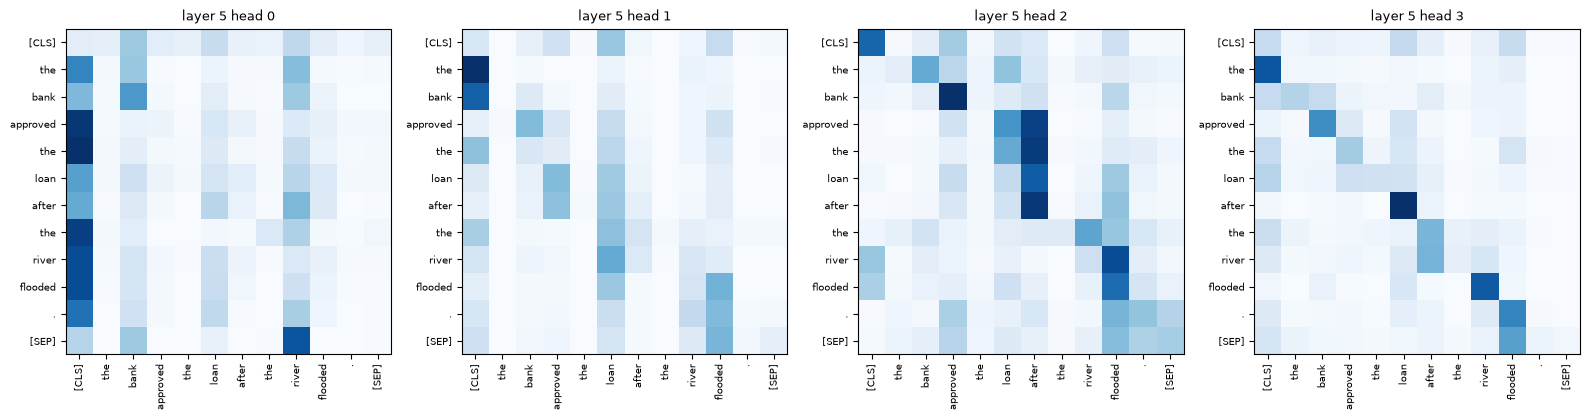

In [25]:
@torch.no_grad()
def show_attention(text, layer=-1):
    enc.eval(); ids = torch.tensor([tok.encode(text, 32)], device=DEVICE); _, att = enc(ids, return_attn=True)
    a = att[layer][0].float().cpu().numpy(); toks = [tok.vocab[i] for i in ids[0].tolist()]; H = a.shape[0]
    fig, axs = plt.subplots(1, min(H, 4), figsize=(4 * min(H, 4), 4))
    for h, ax in enumerate(np.atleast_1d(axs)):
        ax.imshow(a[h], cmap="Blues"); ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=7)
        ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=7); ax.set_title(f"layer {layer % len(att)} head {h}", fontsize=9)
    plt.tight_layout(); plt.show()
show_attention("The bank approved the loan after the river flooded.")

## 5b. Stage 2 of embedding training: retrieval fine-tuning (question → answer sentence)
The NLI stage teaches "same meaning", but search needs "this sentence *answers* that question" (e.g. *won* ↔ *defeated*). With only NLI training the model mostly
matches the **topic**, so every Super Bowl sentence scores alike. Here we continue training on SQuAD **train** (the dev set used for evaluation stays untouched):

* anchor = question, positive = the sentence containing the answer, **hard negative** = another sentence from the *same* paragraph
* sentences are prefixed with their article title (same at index time)
* in-batch candidates that are actually the same sentence as the positive are masked out (no false negatives)

In [26]:
import copy
enc_nli_state = copy.deepcopy(enc.state_dict()); torch.save({"cfg": enc.cfg, "state": enc_nli_state}, f"{OUT}/encoder_nli.pt")   # keep for before/after comparison

def split_sentences(text):                                      # same splitter as section 6
    spans, start = [], 0
    for m in re.finditer(r'(?<=[.!?])\s+(?=[A-Z0-9"\'(\[])', text): spans.append((start, m.start())); start = m.end()
    spans.append((start, len(text))); return spans
def with_title(title, sent): return f"{title.replace('_', ' ')}. {sent}"

sq_tr = load_dataset("rajpurkar/squad", split="train")
if P["qa_rows"]: sq_tr = sq_tr.select(range(min(P["qa_rows"], len(sq_tr))))
QQ, QP, QN, QS_P, QS_N, sid = [], [], [], [], [], {}
for ex in sq_tr:
    c, t = ex["context"], ex["title"]; spans = split_sentences(c)
    if len(spans) < 2: continue
    sents = [c[s:e].strip() for s, e in spans]; st = ex["answers"]["answer_start"][0]
    k = next((i for i, (s, e) in enumerate(spans) if s <= st < e), len(spans) - 1); j = random.choice([i for i in range(len(sents)) if i != k])
    QQ.append(ex["question"]); QP.append(with_title(t, sents[k])); QN.append(with_title(t, sents[j]))
    QS_P.append(sid.setdefault((c, k), len(sid))); QS_N.append(sid.setdefault((c, j), len(sid)))      # sentence identity, for masking duplicates
QS_P, QS_N = np.array(QS_P), np.array(QS_N)
print(f"{len(QQ):,} QA triplets | e.g.\n  Q: {QQ[0]}\n  +: {QP[0]}\n  -: {QN[0]}")
QQ_ids = [tok.encode(x, 64) for x in QQ]; QP_ids = [tok.encode(x, 128) for x in QP]; QN_ids = [tok.encode(x, 128) for x in QN]

steps, bs = P["qa_steps"], P["ft_bs"]; QA_LR = FT_LR; opt = make_opt(enc, QA_LR); n = len(QQ)
CURVES["qa"] = []; run = []; perm = np.random.permutation(n); ptr = 0; t0 = time.time()
for step in range(steps):
    if ptr + bs > n: perm = np.random.permutation(n); ptr = 0
    ix = perm[ptr:ptr + bs]; ptr += bs; enc.train()
    ids = pad_batch([QQ_ids[i] for i in ix] + [QP_ids[i] for i in ix] + [QN_ids[i] for i in ix]).to(DEVICE)
    with amp(): h, _ = enc(ids)
    e = F.normalize(mean_pool(h.float(), ids != PAD), dim=-1); q, cand = e[:bs], e[bs:]
    logits = q @ cand.T * SCALE
    sp, sn = torch.from_numpy(QS_P[ix]).to(DEVICE), torch.from_numpy(QS_N[ix]).to(DEVICE)
    dup = torch.cat([sp, sn])[None, :] == sp[:, None]                      # candidate is the SAME sentence as this question's positive
    dup[torch.arange(bs), torch.arange(bs)] = False                        # ...but never mask the true positive itself
    loss = F.cross_entropy(logits.masked_fill(dup, -1e4), torch.arange(bs, device=DEVICE))
    step_opt(enc, opt, loss, lr_at(step, steps, QA_LR)); run.append(loss.item())
    if (step + 1) % max(1, steps // 40) == 0: CURVES["qa"].append((step + 1, float(np.mean(run)))); run = []
    if (step + 1) % max(1, steps // 10) == 0: print(f"step {step+1:>5}/{steps}  loss {CURVES['qa'][-1][1]:.3f}  ({(time.time()-t0)/60:.1f} min)")
STS["after_qa"] = {s: sts_eval(lambda t: encode_texts(enc, t), s) for s in stsb}
print(f"STS-B after QA stage: val {STS['after_qa']['validation']:.3f} | test {STS['after_qa']['test']:.3f}   (NLI-only was test {STS['after_contrastive']['test']:.3f})")
METRICS["sts"] = STS; METRICS["qa_minutes"] = (time.time() - t0) / 60
torch.save({"cfg": enc.cfg, "state": enc.state_dict()}, f"{OUT}/encoder.pt")      # encoder.pt is now the retrieval-tuned model (NLI-only copy: encoder_nli.pt)

85,617 QA triplets | e.g.
  Q: To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?
  +: University of Notre Dame. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858.
  -: University of Notre Dame. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.
step   400/4000  loss 0.733  (0.3 min)
step   800/4000  loss 0.465  (0.5 min)
step  1200/4000  loss 0.472  (0.8 min)
step  1600/4000  loss 0.310  (1.1 min)
step  2000/4000  loss 0.303  (1.3 min)
step  2400/4000  loss 0.212  (1.6 min)
step  2800/4000  loss 0.159  (1.9 min)
step  3200/4000  loss 0.165  (2.1 min)
step  3600/4000  loss 0.135  (2.4 min)
step  4000/4000  loss 0.140  (2.7 min)
STS-B after QA stage: val 0.785 | test 0.735   (NLI-only was test 0.738)


## 6. Semantic search / question answering on SQuAD v1.1
**Task:** given a question, find the sentence that contains the answer among all sentences of the SQuAD dev-set Wikipedia paragraphs (~10k sentences).
**How it works:** embed every sentence once → embed the question → rank by cosine similarity. The "answer" returned is the best-matching sentence plus its source paragraph (extractive, nothing is generated).
**Metrics** (known gold sentence for each question): Recall@k, MRR. We also build **BM25** (classic keyword search) from scratch as a baseline, and a simple hybrid.
Honest expectation: BM25 is very strong on SQuAD because questions reuse words from the answer sentence. A small from-scratch dense model usually trails it, and the hybrid shows the two are complementary.

**What changed vs. v1 (to fix wrong answers):** (1) the encoder got a retrieval fine-tuning stage on SQuAD *train* question→sentence pairs (section 5b); (2) every sentence is embedded and indexed together with its article title; (3) BM25 ignores stop-words; (4) dense + BM25 are fused with per-question z-scores (the old max-normalised sum let BM25 dominate); (5) an optional cross-encoder re-ranks the top 50.

In [27]:
sq = load_dataset("rajpurkar/squad", split="validation")
nq = P["squad_q"] or len(sq)
ctxs, titles, questions, answers = (list(sq[c])[:nq] for c in ["context", "title", "question", "answers"])

def split_sentences(text):
    spans, start = [], 0
    for m in re.finditer(r'(?<=[.!?])\s+(?=[A-Z0-9"\'(\[])', text): spans.append((start, m.start())); start = m.end()
    spans.append((start, len(text))); return spans

pid_of, paragraphs, para_title, sent_text, sent_para, para_first, para_spans = {}, [], [], [], [], [], []
for c, t in zip(ctxs, titles):
    if c in pid_of: continue
    pid = pid_of[c] = len(paragraphs); paragraphs.append(c); para_title.append(t); para_first.append(len(sent_text)); sp = split_sentences(c); para_spans.append(sp)
    for s, e in sp: sent_text.append(c[s:e].strip()); sent_para.append(pid)
gold_s, gold_p = [], []
for c, a in zip(ctxs, answers):
    pid = pid_of[c]; st = a["answer_start"][0]; k = next(i for i, (s, e) in enumerate(para_spans[pid]) if s <= st < e or i == len(para_spans[pid]) - 1)
    gold_s.append(para_first[pid] + k); gold_p.append(pid)
gold_s, gold_p, para_first_np = np.array(gold_s), np.array(gold_p), np.array(para_first)
print(f"{len(questions):,} questions | {len(paragraphs):,} paragraphs | {len(sent_text):,} sentences to search")

def with_title(title, sent): return f"{title.replace('_', ' ')}. {sent}"          # give each sentence its article context
sent_text_t = [with_title(para_title[sent_para[i]], s_) for i, s_ in enumerate(sent_text)]
print("example indexed text:", sent_text_t[5])


10,570 questions | 2,067 paragraphs | 10,420 sentences to search
example indexed text: Super Bowl 50. They defeated the Arizona Cardinals 49–15 in the NFC Championship Game and advanced to their second Super Bowl appearance since the franchise was founded in 1995.


In [28]:
STOP = set("a an the of in on at to for from by with and or is are was were be been being what which who whom whose when where why how "
           "did does do has have had that this these those it its as into than then also".split())
bm_tokens = lambda t: [w for w in pretokenize(t) if w not in STOP]          # BM25 ignores stop-words (v1 matched on 'which', 'team', 'won'...)

class BM25:
    def __init__(s, docs, k1=1.5, b=0.75):
        toks = [bm_tokens(d) for d in docs]; s.vocab = {}; r, c, v = [], [], []; dl = np.array([max(1, len(t)) for t in toks]); df = Counter()
        for i, t in enumerate(toks):
            for w, n_ in Counter(t).items(): j = s.vocab.setdefault(w, len(s.vocab)); r.append(i); c.append(j); v.append(n_); df[j] += 1
        N = len(docs); idf = np.zeros(len(s.vocab))
        for j, d in df.items(): idf[j] = math.log(1 + (N - d + .5) / (d + .5))
        r, c, v = np.array(r), np.array(c), np.array(v, dtype=float)
        s.W = csr_matrix((idf[c] * v * (k1 + 1) / (v + k1 * (1 - b + b * dl[r] / dl.mean())), (r, c)), shape=(N, len(s.vocab)))
    def score(s, queries):
        r, c = [], []
        for i, q in enumerate(queries):
            for w in set(bm_tokens(q)):
                if w in s.vocab: r.append(i); c.append(s.vocab[w])
        Q = csr_matrix((np.ones(len(r)), (r, c)), shape=(len(queries), len(s.vocab))); return (Q @ s.W.T).toarray()

t0 = time.time()
sent_emb = encode_texts(enc, sent_text_t); q_emb = encode_texts(enc, questions); bm25 = BM25(sent_text_t)      # title-prefixed sentences
print(f"indexed in {time.time()-t0:.0f}s")

# diagnostic: a healthy embedding space has LOW cosine between random sentences (v1 had everything squashed near 0.88)
_r = np.random.RandomState(0).choice(len(sent_emb), min(2000, len(sent_emb)), replace=False); _S = sent_emb[_r] @ sent_emb[_r].T
print(f"mean cosine between random sentences: {_S[np.triu_indices(len(_r), 1)].mean():.2f}")

def retrieval_metrics(score_fn, bs=500):
    rs, rp = [], []
    for i in range(0, len(questions), bs):
        S = score_fn(slice(i, i + bs)); g = gold_s[i:i + bs]
        rs.append(1 + (S > S[np.arange(len(g)), g][:, None]).sum(1))
        Sp = np.maximum.reduceat(S, para_first_np, axis=1); gp = gold_p[i:i + bs]               # paragraph score = best sentence
        rp.append(1 + (Sp > Sp[np.arange(len(gp)), gp][:, None]).sum(1))
    f = lambda r: {"R@1": float((r <= 1).mean()), "R@5": float((r <= 5).mean()), "R@10": float((r <= 10).mean()), "MRR": float((1 / r).mean())}
    return {"sentence": f(np.concatenate(rs)), "paragraph": f(np.concatenate(rp))}

dense = lambda sl: q_emb[sl] @ sent_emb.T
bm = lambda sl: bm25.score(questions[sl])
z = lambda S: (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)       # per-question z-score: puts cosine and BM25 on one scale
def hybrid_z(sl, w=0.5): return z(dense(sl)) + w * z(bm(sl))
def hybrid_rrf(sl, k=60):                                                              # reciprocal-rank fusion (no weight to tune)
    rd, rb = (-dense(sl)).argsort(1).argsort(1), (-bm(sl)).argsort(1).argsort(1); return 1 / (k + rd) + 1 / (k + rb)

# one scalar (the BM25 weight) is chosen from a 4-value grid by sentence-level MRR on dev; everything else is untuned
grid = {w: retrieval_metrics(lambda sl, w=w: hybrid_z(sl, w))["sentence"]["MRR"] for w in [0.25, 0.5, 1.0, 2.0]}
BEST_W = max(grid, key=grid.get); print("BM25 weight sweep (MRR):", {w: round(m, 3) for w, m in grid.items()}, "-> using", BEST_W)
hybrid = lambda sl: hybrid_z(sl, BEST_W)

RET = {}
if "enc_nli_state" in globals():                                                       # before/after: the NLI-only model, indexed the way v1 did
    enc_nli = new_encoder(); enc_nli.load_state_dict(enc_nli_state)
    _se, _qe = encode_texts(enc_nli, sent_text), encode_texts(enc_nli, questions)
    RET["dense (NLI only, v1)"] = retrieval_metrics(lambda sl: _qe[sl] @ _se.T); del enc_nli
RET.update({"dense (ours)": retrieval_metrics(dense), "bm25": retrieval_metrics(bm), "hybrid (z-score)": retrieval_metrics(hybrid), "hybrid (RRF)": retrieval_metrics(hybrid_rrf)})
METRICS["retrieval"] = RET; METRICS["bm25_weight"] = BEST_W
print(f"{'method':<22}{'level':<11}{'R@1':>7}{'R@5':>7}{'R@10':>7}{'MRR':>7}")
for m, d in RET.items():
    for lv, r in d.items(): print(f"{m:<22}{lv:<11}{r['R@1']:>7.3f}{r['R@5']:>7.3f}{r['R@10']:>7.3f}{r['MRR']:>7.3f}")


indexed in 0s
mean cosine between random sentences: 0.02
BM25 weight sweep (MRR): {0.25: 0.763, 0.5: 0.753, 1.0: 0.734, 2.0: 0.718} -> using 0.25
method                level          R@1    R@5   R@10    MRR
dense (NLI only, v1)  sentence     0.339  0.545  0.624  0.436
dense (NLI only, v1)  paragraph    0.435  0.682  0.766  0.548
dense (ours)          sentence     0.556  0.756  0.819  0.648
dense (ours)          paragraph    0.648  0.855  0.910  0.740
bm25                  sentence     0.610  0.793  0.836  0.693
bm25                  paragraph    0.721  0.888  0.921  0.796
hybrid (z-score)      sentence     0.683  0.861  0.899  0.763
hybrid (z-score)      paragraph    0.792  0.939  0.967  0.858
hybrid (RRF)          sentence     0.661  0.840  0.885  0.741
hybrid (RRF)          paragraph    0.762  0.924  0.959  0.834


In [29]:
def ask(question, k=3):
    q = encode_texts(enc, [question])[0]
    sc = z((sent_emb @ q)[None])[0] + BEST_W * z(bm25.score([question]))[0]          # same hybrid as the evaluation
    print("Q:", question)
    for r, i in enumerate(np.argsort(-sc)[:k], 1): print(f"  {r}. [{sc[i]:.2f}] ({para_title[sent_para[i]]}) {sent_text[i]}")
for q in questions[:3]: ask(q)
ask("Which team won Super Bowl 50?"); ask("What causes rain?")


Q: Which NFL team represented the AFC at Super Bowl 50?
  1. [8.76] (Super_Bowl_50) The only other AFC champion team to have worn white as the designated home team in the Super Bowl was the Pittsburgh Steelers; they defeated the Seattle Seahawks 21–10 in Super Bowl XL 10 seasons prior.
  2. [8.72] (Super_Bowl_50) Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season.
  3. [7.80] (Super_Bowl_50) The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super Bowl title.
Q: Which NFL team represented the NFC at Super Bowl 50?
  1. [8.73] (Super_Bowl_50) The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super Bowl title.
  2. [8.33] (Super_Bowl_50) Super Bowl 50 was an American football game to deter

### Optional: cross-encoder re-ranking (pretrained, *not* from scratch)
A bi-encoder embeds question and sentence separately. A **cross-encoder** reads them *together*, which is much more accurate but too slow for the whole corpus,
so we only re-rank the top 50 candidates from the hybrid. Set `USE_RERANKER = False` to stay 100% from-scratch.

In [30]:
USE_RERANKER = True            # uses cross-encoder/ms-marco-MiniLM-L-6-v2 (~90 MB download); False = skip
try:
    assert USE_RERANKER
    %pip install -q sentence-transformers
    from sentence_transformers import CrossEncoder
    ce = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", device=DEVICE)
    TOPN = 50

    def rerank(question, cand):                                  # cand: sentence indices -> same indices, best first
        sc = ce.predict([(question, sent_text_t[i]) for i in cand], batch_size=128, show_progress_bar=False)
        return [cand[j] for j in np.argsort(-sc)]

    def ask_rerank(question, k=3):
        q = encode_texts(enc, [question])[0]; s = z((sent_emb @ q)[None])[0] + BEST_W * z(bm25.score([question]))[0]
        print("Q:", question)
        for r, i in enumerate(rerank(question, list(np.argsort(-s)[:TOPN]))[:k], 1): print(f"  {r}. ({para_title[sent_para[i]]}) {sent_text[i]}")
    ask_rerank("Which team won Super Bowl 50?"); ask_rerank("What causes rain?")

    N = min(500, len(questions)); S = hybrid(slice(0, N)); g = gold_s[:N]
    r_h = 1 + (S > S[np.arange(N), g][:, None]).sum(1); r_r = []
    for qi in range(N):
        order = rerank(questions[qi], list(np.argsort(-S[qi])[:TOPN])); r_r.append(order.index(g[qi]) + 1 if g[qi] in order else 10**6)
    r_r = np.array(r_r); f = lambda r: {"R@1": float((r <= 1).mean()), "R@5": float((r <= 5).mean()), "MRR": float((1 / r).mean())}
    METRICS["rerank_first500"] = {"hybrid": f(r_h), "hybrid+rerank": f(r_r)}
    print(f"first {N} questions, sentence level:"); [print(f"  {k:<14}", {a: round(b, 3) for a, b in v.items()}) for k, v in METRICS["rerank_first500"].items()]
except Exception as e: print("reranker skipped:", e)

Note: you may need to restart the kernel to use updated packages.


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 26496.72it/s]


Q: Which team won Super Bowl 50?
  1. (Super_Bowl_50) The San Francisco Bay Area last hosted in 1985 (Super Bowl XIX), held at Stanford Stadium in Stanford, California, won by the home team 49ers.
  2. (Super_Bowl_50) The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super Bowl title.
  3. (Super_Bowl_50) Denver won despite being massively outgained in total yards (315 to 194) and first downs (21 to 11).
Q: What causes rain?
  1. (Southern_California) Serious rain can occur unusually.
  2. (Oxygen) During periods of lower global temperatures, snow and rain from that evaporated water tends to be higher in oxygen-16, and the seawater left behind tends to be higher in oxygen-18.
  3. (Jacksonville,_Florida) These are caused by the rapid heating of the land relative to the water, combined with extremely high humidity.
first 500 questions, sentence level:
  hybrid         {'R@1'

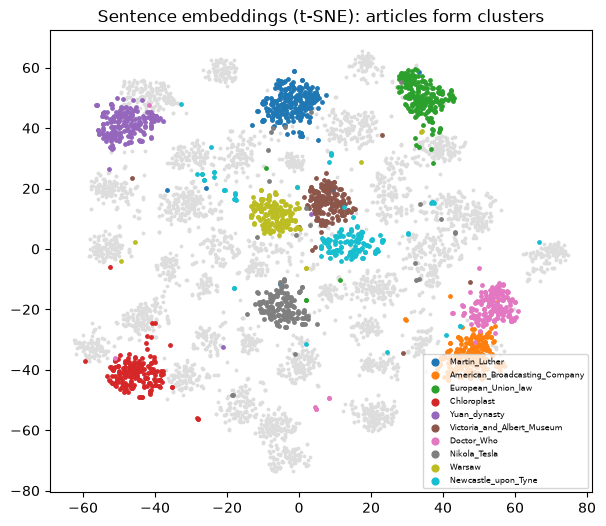

In [31]:
# Map of the search space: t-SNE of sentence embeddings, coloured by Wikipedia article
from sklearn.manifold import TSNE
rng = np.random.RandomState(0); idx = rng.choice(len(sent_text), min(P["tsne_n"], len(sent_text)), replace=False)
xy = TSNE(2, perplexity=min(30, len(idx) // 4), init="pca", random_state=0).fit_transform(sent_emb[idx])
top_titles = [t for t, _ in Counter(para_title[sent_para[i]] for i in idx).most_common(10)]
plt.figure(figsize=(7, 6)); other = np.array([para_title[sent_para[i]] not in top_titles for i in idx]); plt.scatter(*xy[other].T, s=3, c="#ddd")
for t in top_titles:
    m = np.array([para_title[sent_para[i]] == t for i in idx]); plt.scatter(*xy[m].T, s=6, label=t)
plt.legend(fontsize=6, markerscale=2); plt.title("Sentence embeddings (t-SNE): articles form clusters"); plt.show()

### Optional: how far from the ceiling?
Plug a strong pre-trained model into the *same* evaluation code (needs `pip install sentence-transformers`, ~90 MB download). Do this only as a reference point for the audience.

In [32]:
try:
    %pip install -q sentence-transformers
    from sentence_transformers import SentenceTransformer
    ref = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
    ref_enc = lambda t: ref.encode(list(t), batch_size=128, normalize_embeddings=True)
    ref_sent, ref_q = ref_enc(sent_text), ref_enc(questions)
    METRICS["reference_all_MiniLM_L6_v2"] = {"sts_test": sts_eval(ref_enc, "test"), "retrieval": retrieval_metrics(lambda sl: ref_q[sl] @ ref_sent.T)}
    print(METRICS["reference_all_MiniLM_L6_v2"])
except Exception as e: print("reference skipped:", e)

Note: you may need to restart the kernel to use updated packages.


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 27675.42it/s]


{'sts_test': 0.8203013947512559, 'retrieval': {'sentence': {'R@1': 0.5660359508041627, 'R@5': 0.7858088930936613, 'R@10': 0.8452223273415327, 'MRR': 0.6658497325883691}, 'paragraph': {'R@1': 0.7012298959318827, 'R@5': 0.9012298959318827, 'R@10': 0.9420056764427626, 'MRR': 0.7909013285903445}}}


## 7. Export everything for the interactive web demo

In [33]:
import shutil
json.dump(dict(sentences=sent_text, sent_para=sent_para, para_title=para_title, paragraphs=paragraphs), open(f"{OUT}/corpus.json", "w"))
np.save(f"{OUT}/sent_emb.npy", sent_emb.astype(np.float16)); np.save(f"{OUT}/tsne_idx.npy", idx); np.save(f"{OUT}/tsne_xy.npy", xy.astype(np.float32))
json.dump(METRICS, open(f"{OUT}/metrics.json", "w"), indent=1); json.dump(CURVES, open(f"{OUT}/curves.json", "w"))
json.dump({"vocab_freq": freq.tolist()}, open(f"{OUT}/vocab_freq.json", "w"))
zip_path = shutil.make_archive("artifacts", "zip", OUT); print("saved:", sorted(os.listdir(OUT)), "->", zip_path)
try:
    from google.colab import files; files.download(zip_path)       # on Colab: downloads the zip; skip if running locally
except Exception: pass

saved: ['corpus.json', 'curves.json', 'encoder.pt', 'encoder_mlm.pt', 'encoder_nli.pt', 'metrics.json', 'sent_emb.npy', 'tokenizer.json', 'tsne_idx.npy', 'tsne_xy.npy', 'vocab_freq.json'] -> /RnD-Drive/uttham/embedding/artifacts.zip
